# Лабораторная работа 1: сравнение mean pooling и cls pooling

**Цель:** выполнить семь пунктов задания и сравнить стратегии пулинга в задаче классификации текстов.

**Задачи:**

1. Выбрать датасет для задачи классификации текстов (https://huggingface.co/datasets)
2. Выбрать модель векторизации (https://huggingface.co/models)
3. Обучить классификатор с mean_pooling.
4. Посчитать метрики: F1-Score, Precision, Recall.
5. Обучить классификатор с cls_pooling.
6. Посчитать метрики: F1-Score, Precision, Recall.
7. Сравнить метрики полученные при использовании разных стратегий пулинга

**Архитектура:** текст -> токенизатор -> замороженный BERT-tiny -> mean_pooling / cls_pooling -> отдельная LogisticRegression -> класс отзыва.

Датасет: `cornell-movie-review-data/rotten_tomatoes`.
Модель векторизации: `prajjwal1/bert-tiny`.
Задача: отрицательный (0) или положительный (1) отзыв.

Обучаются **два отдельных классификатора**. Параметры BERT не обновляются.
Это вариант с извлечением признаков, а не дообучение трансформера.
В приведённом задании требуется обучить классификатор; отдельного требования
дообучать векторизатор нет.

**Статус:** код подготовлен для запуска; результаты полного эксперимента не подставлены.
Ячейки следует выполнять сверху вниз. Для первого запуска нужен интернет.


### Библиотеки и общие настройки

Используем 2000 обучающих примеров, батч из 32 текстов и не более 128 токенов на текст.
Seed фиксирует случайный отбор данных. Вывод версий библиотек следует сохранить в отчёте.
Данные и настройки общие для двух экспериментов.


In [1]:
import numpy as np
import pandas as pd
import torch

from collections import Counter
from importlib.metadata import version
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModel
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support
from tqdm.auto import tqdm

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("plots")
output_dir.mkdir(exist_ok=True)

SEED = 42
MODEL_NAME = "prajjwal1/bert-tiny"
DATASET_NAME = "cornell-movie-review-data/rotten_tomatoes"

TRAIN_SIZE = 4000
BATCH_SIZE = 32
MAX_LENGTH = 128

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Устройство:", DEVICE)

for package in ("torch", "transformers", "datasets", "scikit-learn"):
    print(package, version(package))


/home/lonaogoda/spailb/.venvconvlb/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Устройство: cpu
torch 2.14.0+cpu
transformers 4.57.6
datasets 5.0.1
scikit-learn 1.7.2


## 1. Выбор датасета для задачи классификации текстов

Выбран [Rotten Tomatoes](https://huggingface.co/datasets/cornell-movie-review-data/rotten_tomatoes).
Это англоязычные фрагменты отзывов о фильмах с метками 0 = negative, 1 = positive.

В датасете 8530 примеров train, 1066 validation и 1066 test.
Для снижения нагрузки отбираем 2000 примеров **только из train** со стратификацией.
Официальный test используем полностью и не смешиваем с train.

Validation не используется: настройки фиксированы заранее и не подбираются по результатам test.
При подборе гиперпараметров нужна отдельная валидационная выборка.


In [46]:
dataset = load_dataset(DATASET_NAME)

train_data = dataset["train"]
test_data = dataset["test"]

if not 2 <= TRAIN_SIZE <= len(train_data):
    raise ValueError("TRAIN_SIZE должен быть от 2 до размера обучающей выборки.")

# Отбираем примеры только из train, сохраняя доли классов.
# Неиспользованный остаток train не становится нашей тестовой выборкой.
if TRAIN_SIZE < len(train_data):
    train_data = train_data.train_test_split(
        train_size=TRAIN_SIZE,
        stratify_by_column="label",
        seed=SEED,
    )["train"]

train_texts = list(train_data["text"])
test_texts = list(test_data["text"])

y_train = np.asarray(train_data["label"])
y_test = np.asarray(test_data["label"])

print("Train:", len(train_texts), Counter(y_train))
print("Test:", len(test_texts), Counter(y_test))
print("Названия классов:", dataset["train"].features["label"].names)
print("Пример:", train_texts[0])
print("Метка:", int(y_train[0]))


Train: 4000 Counter({np.int64(0): 2000, np.int64(1): 2000})
Test: 1066 Counter({np.int64(1): 533, np.int64(0): 533})
Названия классов: ['neg', 'pos']
Пример: the script by vincent r . nebrida . . . tries to cram too many ingredients into one small pot .
Метка: 0


## 2. Выбрать модель векторизации

Выбрана [prajjwal1/bert-tiny](https://huggingface.co/prajjwal1/bert-tiny):
предобученный англоязычный BERT с 2 слоями и размерностью скрытого вектора 128.

requires_grad_(False) отключает градиенты параметров.
eval() переводит энкодер в режим оценки, в частности отключает dropout.
Сам по себе eval() не замораживает параметры.

Токенизатор добавляет [CLS] в начало текста. Используем дополнение справа,
чтобы [CLS] оставался на позиции 0.


In [47]:
import sys
import transformers

print("Python:", sys.executable)
print("Transformers:", transformers.__version__)
print("Модель:", MODEL_NAME)

Python: /home/lonaogoda/spailb/.venvconvlb/bin/python
Transformers: 4.57.6
Модель: prajjwal1/bert-tiny


In [48]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.padding_side = "right"

encoder = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE)

encoder.requires_grad_(False)
encoder.eval()

print("Размерность вектора:", encoder.config.hidden_size)
print("Число слоёв:", encoder.config.num_hidden_layers)
print("Токены:", tokenizer.tokenize("This movie was really good."))


Размерность вектора: 128
Число слоёв: 2
Токены: ['this', 'movie', 'was', 'really', 'good', '.']


### Подготовка признаков: две функции пулинга

Энкодер выдаёт last_hidden_state формы [batch, tokens, 128].
Пулинг преобразует его в [batch, 128]: один вектор на текст.

**mean_pooling:** усредняем скрытые состояния токенов по маске.
Позиции [PAD] исключаем; [CLS] и [SEP] включаем в среднее.

**cls_pooling:** берём last_hidden_state[:, 0, :], то есть контекстный вектор
[CLS] после последнего слоя. 

Пулинг не обучается: обучаются классификаторы на полученных признаках.


In [49]:
def mean_pooling(
    hidden_states: torch.Tensor,
    attention_mask: torch.Tensor,
) -> torch.Tensor:
    mask = attention_mask.unsqueeze(-1).to(hidden_states.dtype)

    vector_sum = (hidden_states * mask).sum(dim=1)
    token_count = mask.sum(dim=1).clamp(min=1)

    return vector_sum / token_count


def cls_pooling(hidden_states: torch.Tensor) -> torch.Tensor:
    return hidden_states[:, 0, :]


### Получить признаки для train и test

Обе стратегии считаются из одного прохода BERT, чтобы не повторять одинаковые вычисления.
no_grad() отключает построение графа градиентов.

Ожидаемые размеры: обе train-матрицы (2000, 128),
обе test-матрицы (1066, 128).
Порядок отзывов остаётся одинаковым, поэтому для обоих представлений используются
те же y_train и y_test.

На этом этапе происходит только векторизация, **ещё не обучение классификаторов**.


In [50]:
@torch.no_grad()
def extract_embeddings(texts: list[str]) -> tuple[np.ndarray, np.ndarray]:
    if not texts:
        raise ValueError("Список текстов не должен быть пустым.")

    mean_vectors = []
    cls_vectors = []

    for start in tqdm(range(0, len(texts), BATCH_SIZE), desc="Векторизация"):
        batch_texts = texts[start:start + BATCH_SIZE]

        inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt",
        )
        inputs = {key: value.to(DEVICE) for key, value in inputs.items()}

        # Один проход энкодера для обеих стратегий
        hidden = encoder(**inputs).last_hidden_state

        mean_batch = mean_pooling(hidden, inputs["attention_mask"])
        cls_batch = cls_pooling(hidden)

        mean_vectors.append(mean_batch.cpu().numpy())
        
        cls_vectors.append(cls_batch.cpu().numpy().copy())

    return (
        np.concatenate(mean_vectors, axis=0),
        np.concatenate(cls_vectors, axis=0),
    )


X_train_mean, X_train_cls = extract_embeddings(train_texts)
X_test_mean, X_test_cls = extract_embeddings(test_texts)

print("Train mean / CLS:", X_train_mean.shape, X_train_cls.shape)
print("Test mean / CLS:", X_test_mean.shape, X_test_cls.shape)

assert X_train_mean.shape == X_train_cls.shape == (len(y_train), encoder.config.hidden_size)
assert X_test_mean.shape == X_test_cls.shape == (len(y_test), encoder.config.hidden_size)
assert np.isfinite(X_train_mean).all() and np.isfinite(X_train_cls).all()
assert np.isfinite(X_test_mean).all() and np.isfinite(X_test_cls).all()


Векторизация: 100%|██████████| 34/34 [00:00<00:00, 74.37it/s]

Train mean / CLS: (4000, 128) (4000, 128)
Test mean / CLS: (1066, 128) (1066, 128)


## 3. Обучить классификатор с mean_pooling

Создаём первый экземпляр LogisticRegression.
Метод fit(X_train_mean, y_train) обучает его коэффициенты на train-признаках.

Название «логистическая регрессия» не меняет её назначения: здесь это классификатор.
max_iter=1000 — предел числа итераций оптимизатора классификатора, не эпохи BERT.


In [51]:
mean_classifier = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    max_iter=1000,
)

mean_classifier.fit(X_train_mean, y_train)

print("Классификатор с mean_pooling обучен.")
print("Размер матрицы коэффициентов:", mean_classifier.coef_.shape)


Классификатор с mean_pooling обучен.
Размер матрицы коэффициентов: (1, 128)


## 4. Посчитать F1-Score, Precision, Recall для mean_pooling

Сначала получаем предсказания на test, затем сравниваем их с истинными метками y_test.

Используем average="macro": каждая метрика рассчитывается для каждого класса,
затем усредняется с равным весом классов.
Macro-F1 — среднее F1 классов, а не F1 от усреднённых Precision и Recall.

precision_recall_fscore_support возвращает значения в порядке:
Precision, Recall, F1, support. В сводной таблице выводим F1, Precision, Recall.


In [52]:
# Предсказываем классы только для тестовой выборки.
mean_predictions = mean_classifier.predict(X_test_mean)

mean_precision, mean_recall, mean_f1, _ = precision_recall_fscore_support(
    y_test,
    mean_predictions,
    labels=[0, 1],
    average="macro",
    zero_division=0,
)

mean_metrics = {
    "F1_macro": mean_f1,
    "Precision_macro": mean_precision,
    "Recall_macro": mean_recall,
}

print("Результаты mean_pooling:")
for metric, value in mean_metrics.items():
    print(f"{metric}: {value:.4f}")


Результаты mean_pooling:
F1_macro: 0.6885
Precision_macro: 0.6886
Recall_macro: 0.6886


## 5. Обучить классификатор с cls_pooling

Создаём **новый** экземпляр LogisticRegression с теми же настройками.
Обучение выполняется на X_train_cls и тех же метках y_train.
Веса первого классификатора не используются.


In [53]:
cls_classifier = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    max_iter=1000,
)

cls_classifier.fit(X_train_cls, y_train)

print("Классификатор с cls_pooling обучен.")
print("Размер матрицы коэффициентов:", cls_classifier.coef_.shape)


Классификатор с cls_pooling обучен.
Размер матрицы коэффициентов: (1, 128)


## 6. Посчитать F1-Score, Precision, Recall для cls_pooling

Используем ту же тестовую выборку и тот же способ усреднения.
Получаем второй независимый набор из трёх метрик.


In [54]:
cls_predictions = cls_classifier.predict(X_test_cls)

cls_precision, cls_recall, cls_f1, _ = precision_recall_fscore_support(
    y_test,
    cls_predictions,
    labels=[0, 1],
    average="macro",
    zero_division=0,
)

cls_metrics = {
    "F1_macro": cls_f1,
    "Precision_macro": cls_precision,
    "Recall_macro": cls_recall,
}

print("Результаты cls_pooling:")
for metric, value in cls_metrics.items():
    print(f"{metric}: {value:.4f}")


Результаты cls_pooling:
F1_macro: 0.6744
Precision_macro: 0.6747
Recall_macro: 0.6745


## 7. Сравнить метрики разных стратегий пулинга

Таблица содержит две строки и три метрики. Отдельно выводим разность mean − CLS.
Основной критерий — Macro-F1; он выбран заранее.

Сравнение контролируемое: тексты, разбиение, модель векторизации, длина входа
и настройки классификатора одинаковые. Меняется стратегия пулинга.

Более высокую метрику в одном запуске нельзя автоматически считать
статистически значимым или универсальным преимуществом.


In [55]:
results = pd.DataFrame(
    [mean_metrics, cls_metrics],
    index=["mean_pooling", "cls_pooling"],
)
results.index.name = "pooling"

print("Метрики на одной и той же тестовой выборке:")
print(results.round(4).to_string())

difference = results.loc["mean_pooling"] - results.loc["cls_pooling"]
print("\nРазница mean - CLS:")
print(difference.round(4).to_string())

delta_f1 = float(difference["F1_macro"])
if delta_f1 > 0:
    print(f"В этом запуске F1_macro выше у mean_pooling на {delta_f1:.4f}.")
elif delta_f1 < 0:
    print(f"В этом запуске F1_macro выше у cls_pooling на {-delta_f1:.4f}.")
else:
    print("В этом запуске значения F1_macro совпали.")

results.to_csv("pooling_results.csv", encoding="utf-8")
print("\nТаблица сохранена в pooling_results.csv")


Метрики на одной и той же тестовой выборке:
              F1_macro  Precision_macro  Recall_macro
pooling                                              
mean_pooling    0.6885           0.6886        0.6886
cls_pooling     0.6744           0.6747        0.6745

Разница mean - CLS:
F1_macro           0.0141
Precision_macro    0.0139
Recall_macro       0.0141
В этом запуске F1_macro выше у mean_pooling на 0.0141.

Таблица сохранена в pooling_results.csv


In [56]:
from sklearn.metrics import f1_score

for name, classifier, X_train, X_test in (
    ("mean_pooling", mean_classifier, X_train_mean, X_test_mean),
    ("cls_pooling", cls_classifier, X_train_cls, X_test_cls),
):
    train_f1 = f1_score(
        y_train,
        classifier.predict(X_train),
        average="macro",
        zero_division=0,
    )

    test_f1 = f1_score(
        y_test,
        classifier.predict(X_test),
        average="macro",
        zero_division=0,
    )

    print(
        f"{name}: "
        f"F1 train = {train_f1:.4f}, "
        f"F1 test = {test_f1:.4f}"
    )

mean_pooling: F1 train = 0.7149, F1 test = 0.6885
cls_pooling: F1 train = 0.7077, F1 test = 0.6744


Для mean pooling получены значения 0,7253 и 0,6820 соответственно, для CLS pooling — 0,7260 и 0,6716. Снижение F1 составило 0,0433 и 0,0544. Таким образом, при практически одинаковом качестве на обучающих данных mean pooling обеспечил более высокий результат на тестовой выборке. Умеренные значения обучающего F1 позволяют предположить, что качество ограничивается не только переносом на новые данные, но и выбранными признаками и классификатором. Для установления причин необходимы дополнительные эксперименты.

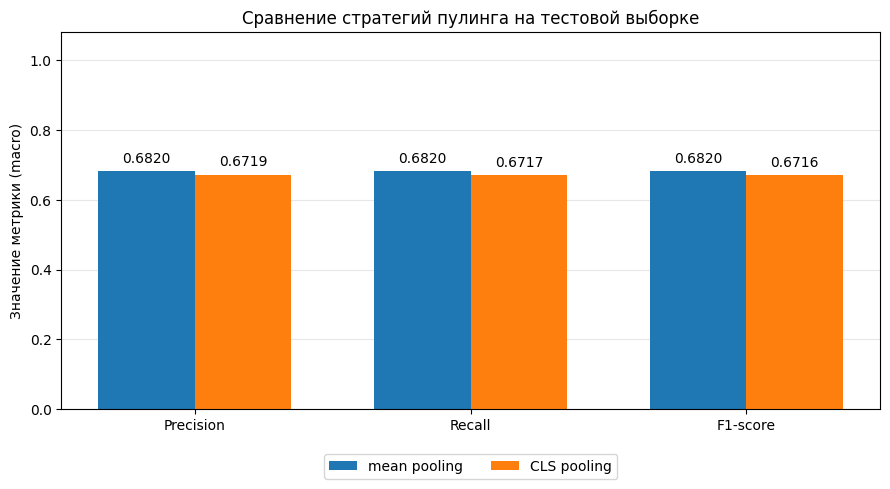

In [ ]:
metric_columns = ["Precision_macro", "Recall_macro", "F1_macro"]
metric_labels = ["Precision", "Recall", "F1-score"]


plot_data = results.loc[
    ["mean_pooling", "cls_pooling"],
    metric_columns,
].astype(float)

x = np.arange(len(metric_columns))
width = 0.35

fig = plt.figure(figsize=(9, 5))
ax = fig.gca()

bars_mean = ax.bar(
    x - width / 2,
    plot_data.loc["mean_pooling"],
    width,
    label="mean pooling",
)

bars_cls = ax.bar(
    x + width / 2,
    plot_data.loc["cls_pooling"],
    width,
    label="CLS pooling",
)

ax.bar_label(bars_mean, fmt="%.4f", padding=4)
ax.bar_label(bars_cls, fmt="%.4f", padding=4)

ax.set_xticks(x)
ax.set_xticklabels(metric_labels)

ax.set_ylim(0, 1.08)
ax.set_yticks(np.linspace(0, 1, 6))

ax.set_ylabel("Значение метрики (macro)")
ax.set_title("Сравнение стратегий пулинга на тестовой выборке")

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=2,
)

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(
    output_dir / "pooling_metrics.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

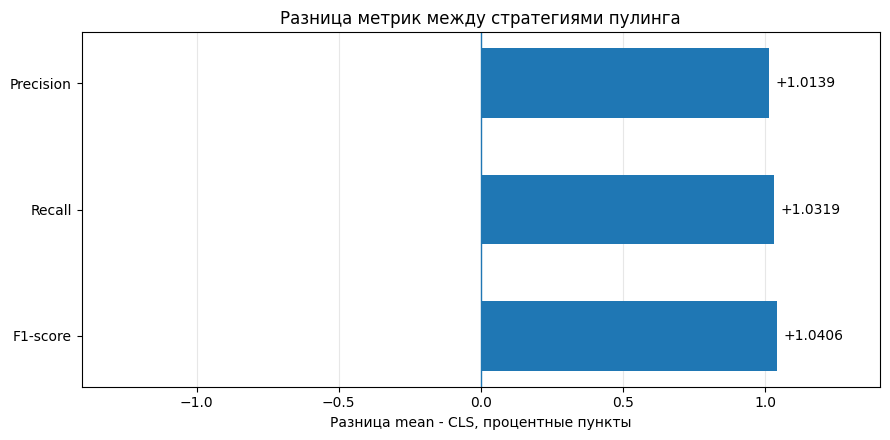

Графики сохранены в папке: /home/lonaogoda/spailb/plots


In [ ]:
# Разница между стратегиями в процентных пунктах
difference_pp = 100 * (
    plot_data.loc["mean_pooling"]
    - plot_data.loc["cls_pooling"]
)

fig = plt.figure(figsize=(9, 4.5))
ax = fig.gca()

bars = ax.barh(
    metric_labels,
    difference_pp.to_numpy(),
    height=0.55,
)

# Нулевая линия означает отсутствие разницы
ax.axvline(0, linewidth=1)

ax.bar_label(bars, fmt="%+.4f", padding=5)

limit = max(
    float(difference_pp.abs().max()) * 1.35,
    0.01,
)
ax.set_xlim(-limit, limit)

ax.invert_yaxis()

ax.set_xlabel("Разница mean - CLS, процентные пункты")
ax.set_title("Разница метрик между стратегиями пулинга")

ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()
fig.savefig(
    output_dir / "pooling_difference.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Графики сохранены в папке:", output_dir.resolve())

### Выводы:

В ходе лабораторной работы была реализована классификация тональности отзывов из датасета **Rotten Tomatoes** с использованием предобученной модели **BERT-tiny (prajjwal1/bert-tiny)**. Модель применялась как векторизатор с фиксированными весами, а для определения классов текстов обучались два отдельных классификатора на основе логистической регрессии.

Были реализованы и сравнены две стратегии получения векторного представления текста: **mean pooling**, при котором усредняются выходные векторы токенов с исключением позиций заполнения [PAD], и **CLS pooling**, при котором используется выходной вектор специального токена [CLS] после последнего слоя энкодера. Для обоих вариантов использовались одинаковые обучающие и тестовые данные, а также одинаковые настройки классификаторов.

Качество оценивалось по метрикам Precision, Recall и F1-score с macro-усреднением. При использовании **mean pooling** все три метрики при округлении до четырёх знаков составили **0,6820**. Для **CLS pooling** получены значения **Precision_macro = 0,6719**, **Recall_macro = 0,6717** и **F1_macro = 0,6716**.

Сравнение показало **небольшое преимущество mean pooling по всем трём метрикам**. По основному критерию F1_macro разница составила **0,0104**, что соответствует приблизительно **1,04 процентного пункта**. Преимущество по Precision_macro составило **0,0101**, а по Recall_macro **0,0103**. Таким образом, в проведённом эксперименте усреднение выходных векторов токенов позволило получить несколько более высокое качество классификации, чем использование только представления [CLS].

Цель лабораторной работы достигнута: выбраны датасет и модель векторизации, реализованы две стратегии пулинга, обучены соответствующие классификаторы, рассчитаны и сопоставлены метрики. Полученный результат относится к выбранной модели, данным и режиму без дообучения энкодера. Статистическая значимость различий не проверялась, поэтому результаты одного запуска не позволяют утверждать, что mean pooling будет превосходить CLS pooling во всех задачах.



**Для завершения работы:** выполнить все ячейки, сохранить ноутбук с выводами,
приложить итоговую таблицу и написать вывод по реально полученным значениям.
Файл с кодом без результатов запуска ещё не подтверждает выполнение эксперимента.

### Документация

- [Датасет Rotten Tomatoes](https://huggingface.co/datasets/cornell-movie-review-data/rotten_tomatoes)
- [BERT-tiny](https://huggingface.co/prajjwal1/bert-tiny)
- [Выходы моделей Transformers](https://huggingface.co/docs/transformers/main_classes/output)
- [Стратегии пулинга](https://www.sbert.net/docs/sentence_transformer/usage/custom_models.html)
- [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)
- [Precision, Recall и F1](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html)
